In [60]:
import cv2
import numpy as np
from matplotlib import pyplot as plt

import os
from pathlib import Path

In [2]:

# this is for Local Binary Patterns
    
def get_pixel(img, center, x, y):
    
    new_value = 0
    
    try:
        # If local neighbourhood pixel 
        # value is greater than or equal
        # to center pixel values then 
        # set it to 1
        if img[x][y] >= center:
            new_value = 1
            
    except:
        # Exception is required when 
        # neighbourhood value of a center
        # pixel value is null i.e. values
        # present at boundaries.
        pass
    
    return new_value
 
# Function for calculating LBP
def lbp_calculated_pixel(img, x, y):
 
    center = img[x][y]
 
    val_ar = []
    
    # top_left
    val_ar.append(get_pixel(img, center, x-1, y-1))
    
    # top
    val_ar.append(get_pixel(img, center, x-1, y))
    
    # top_right
    val_ar.append(get_pixel(img, center, x-1, y + 1))
    
    # right
    val_ar.append(get_pixel(img, center, x, y + 1))
    
    # bottom_right
    val_ar.append(get_pixel(img, center, x + 1, y + 1))
    
    # bottom
    val_ar.append(get_pixel(img, center, x + 1, y))
    
    # bottom_left
    val_ar.append(get_pixel(img, center, x + 1, y-1))
    
    # left
    val_ar.append(get_pixel(img, center, x, y-1))
     
    # Now, we need to convert binary
    # values to decimal
    power_val = [1, 2, 4, 8, 16, 32, 64, 128]
 
    val = 0
    
    for i in range(len(val_ar)):
        val += val_ar[i] * power_val[i]
        
    return val
 

 


In [26]:
path = r"C:\Users\bamilosin\Documents\500L\coursework\cpe503 - embedded sys\cfd\cfd\CFD Version 3.0.1\Images\CFD-MR\CFD-MF-354-067-N.jpg"
img_bgr = cv2.imread(path, 1)
 
height, width = (256, 256)
 
# We need to convert RGB image 
# into gray one because gray 
# image has one channel only.
img_gray = cv2.cvtColor(img_bgr,
                        cv2.COLOR_BGR2GRAY)

img_gray = cv2.resize(img_gray, (height, width), interpolation=cv2.INTER_LINEAR) # resized
 
# Create a numpy array as 
# the same height and width 
# of RGB image
img_lbp = np.zeros((height, width),
                   np.uint8)
 
for i in range(0, height):
    for j in range(0, width):
        img_lbp[i, j] = lbp_calculated_pixel(img_gray, i, j)

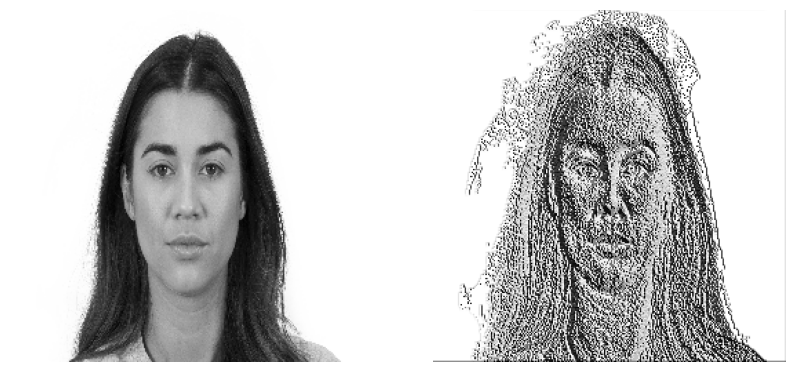

In [28]:
fig, axs = plt.subplots(figsize=(10, 5), nrows=1, ncols=2)
axs[1].imshow(img_lbp, cmap="gray")
axs[1].axis(False)
axs[0].imshow(cv2.cvtColor(img_gray, cv2.COLOR_BGR2RGB), cmap="viridis")
axs[0].axis(False)
plt.show()

## histogram 

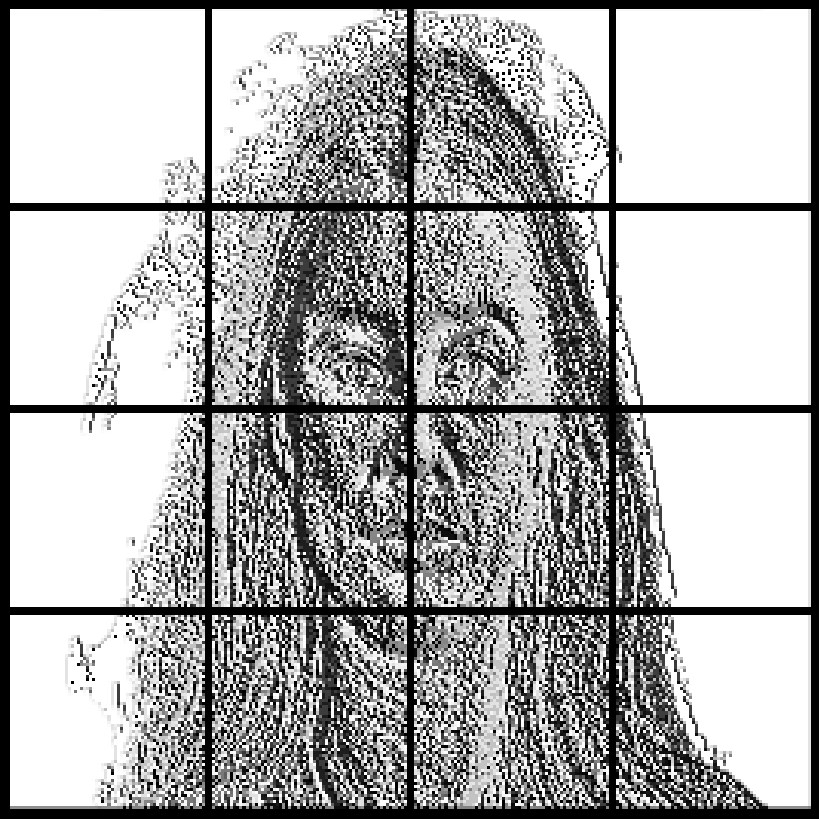

In [54]:
grid = 4 # 4 x 4 = 16 blocks
fig, axs = plt.subplots(grid, grid, figsize=(8, 8), facecolor="black")
fig.subplots_adjust(left=0, right=1, bottom=0, top=1, wspace=0.04, hspace=0.04)
for ax, block in zip(axs.ravel(), blocks):
    ax.imshow(block, cmap="gray", vmin=0, vmax=255)
    ax.axis("off")
plt.show()



grid = 4  
hists = []

for rows in np.array_split(img_lbp, grid, axis=0):
    for block in np.array_split(rows, grid, axis=1):
        h, _ = np.histogram(block.ravel(), bins=256, range=(0, 256))
        hists.append(h / block.size)       # normalised so every block sums to 1

feature_vector = np.concatenate(hists)     # shape (16 * 256,) = (4096,)

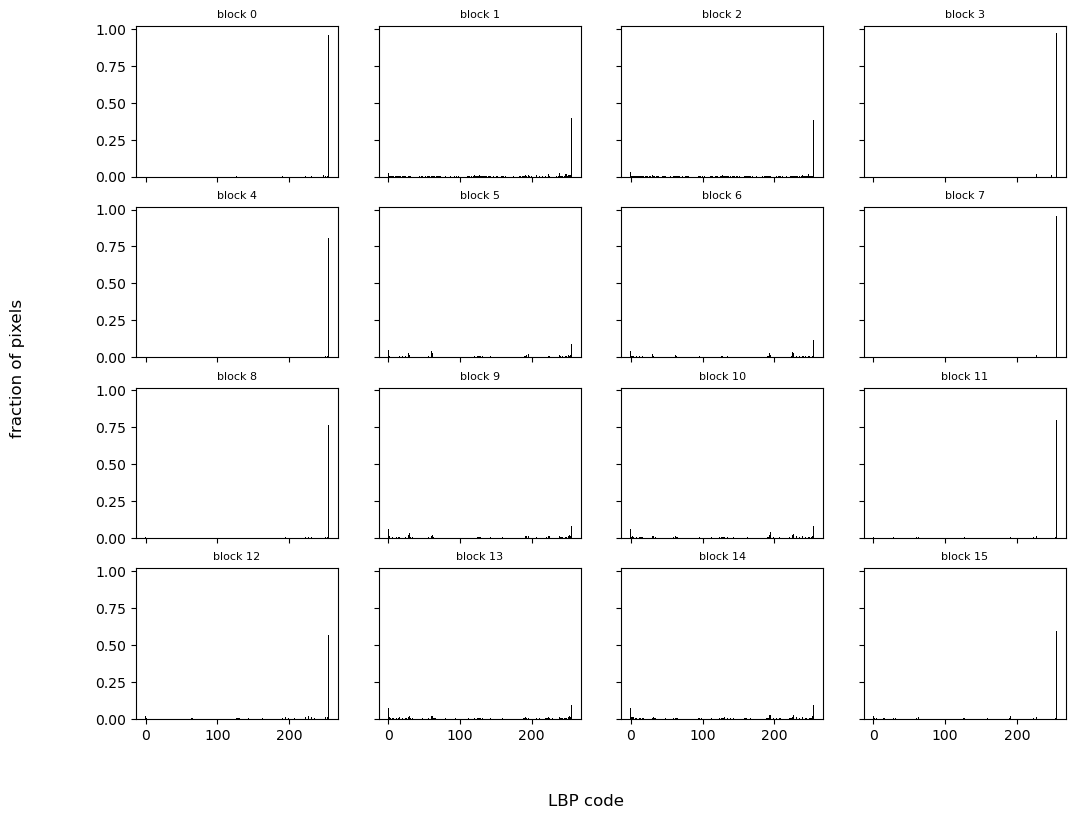

In [53]:
# plot histograms 
blocks = [b for rows in np.array_split(img_lbp, grid, axis=0)
            for b in np.array_split(rows, grid, axis=1)]

fig, axs = plt.subplots(grid, grid, figsize=(12, 9), sharex=True, sharey=True)
for k, (ax, block) in enumerate(zip(axs.ravel(), blocks)):
    h, _ = np.histogram(block.ravel(), bins=256, range=(0, 256))
    ax.bar(np.arange(256), h / block.size, width=1.0, color="k")
    ax.set_title(f"block {k}", fontsize=8)
fig.supxlabel("LBP code")
fig.supylabel("fraction of pixels")
# fig.tight_layout()
plt.show()

In [69]:
# do for all images and save to a csv, open in pandas and randomly add labels
data_path = r"C:\Users\bamilosin\Documents\500L\coursework\cpe503 - embedded sys\cfd\cfd\CFD Version 3.0.1\Images\CFD-MR"

def get_lbp_and_histogram(image_path, target_size:tuple=(256, 256), n_bins:int=256):
    """Loads, converts to gray, resizes, and extracts normalized LBP histogram."""

    height, width = target_size
    # Read the image (handles both RGB or Grayscale paths safely)
    img = cv2.imread(image_path)
    if img is None:
        return None
    
    # Convert to grayscale
    gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
    
    # Resize to standardize processing size across the dataset
    resized = cv2.resize(gray, target_size, interpolation=cv2.INTER_AREA)
    
    # Extract LBP map
    img_lbp = np.zeros((height, width), np.uint8)

    for i in range(0, height):
        for j in range(0, width):
            img_lbp[i, j] = lbp_calculated_pixel(img_gray, i, j)


    # extract histogram
    grid = 4  # should be soft coded!!!
    hists = []

    for rows in np.array_split(img_lbp, grid, axis=0):
        for block in np.array_split(rows, grid, axis=1):
            h, _ = np.histogram(block.ravel(), bins=256, range=(0, 256))
            hists.append(h / block.size)       # normalised so every block sums to 1

    hist_feats = np.concatenate(hists)     # shape (16 * 256,) = (4096,)
    
    return img_lbp, hist_feats


lbp, hists = get_lbp_and_histogram(path)

In [ ]:
# process data for all images in dataset
data_path = Path(r"C:\Users\bamilosin\Documents\500L\coursework\cpe503 - embedded sys\cfd\cfd\CFD Version 3.0.1\Images\CFD-MR")
for i, image in enumerate (os.listdir(data_path)):''
    print(i, image)

0 CFD-MF-300-002-N.jpg
1 CFD-MF-301-024-N.jpg
2 CFD-MF-302-027-N.jpg
3 CFD-MF-303-013-N.jpg
4 CFD-MF-304-018-N.jpg
5 CFD-MF-305-014-N.jpg
6 CFD-MF-306-003-N.jpg
7 CFD-MF-307-002-N.jpg
8 CFD-MF-308-001-N.jpg
9 CFD-MF-309-002-N.jpg
10 CFD-MF-310-027-N.jpg
11 CFD-MF-311-001-N.jpg
12 CFD-MF-312-002-N.jpg
13 CFD-MF-313-002-N.jpg
14 CFD-MF-314-001-N.jpg
15 CFD-MF-315-002-N.jpg
16 CFD-MF-316-001-N.jpg
17 CFD-MF-317-002-N.jpg
18 CFD-MF-318-022-N.jpg
19 CFD-MF-319-016-N.jpg
20 CFD-MF-320-002-N.jpg
21 CFD-MF-321-003-N.jpg
22 CFD-MF-322-020-N.jpg
23 CFD-MF-323-001-N.jpg
24 CFD-MF-324-031-N.jpg
25 CFD-MF-325-002-N.jpg
26 CFD-MF-326-016-N.jpg
27 CFD-MF-327-002-N.jpg
28 CFD-MF-328-020-N.jpg
29 CFD-MF-329-001-N.jpg
30 CFD-MF-330-001-N.jpg
31 CFD-MF-331-010-N.jpg
32 CFD-MF-332-014-N.jpg
33 CFD-MF-333-012-N.jpg
34 CFD-MF-334-002-N.jpg
35 CFD-MF-335-002-N.jpg
36 CFD-MF-336-016-N.jpg
37 CFD-MF-337-026-N.jpg
38 CFD-MF-338-001-N.jpg
39 CFD-MF-339-002-N.jpg
40 CFD-MF-340-026-N.jpg
41 CFD-MF-341-018-N.jpg
42

### Classifier

In [ ]:
from sklearn.linear_model import LogisticRegression

lr_model = LogisticRegression()
lr_model

,penalty,'l2'
,dual,False
,tol,0.0001
,C,1.0
,fit_intercept,True
,intercept_scaling,1
,class_weight,None
,random_state,None
,solver,'lbfgs'
,max_iter,100
,multi_class,'deprecated'
